# Quiz 2：Sentiment Analysis（20 分）

**蘇芯儀 / Sharon0726**

建立與訓練 RNN（5）、test 推論（5）、LSTM（5）、兩模型評估比較（5）。

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
R=Path('results')
assert R.exists(), 'Run from Week4; results/ is required.'
def read(name): return json.loads((R/name).read_text(encoding='utf-8'))
def show(name): display(Image(filename=str(R/'figures'/name)))


## 模型

128 維 embedding → 128 hidden RNN 或 LSTM → dropout → 二類分類。取最後有效詞，不取補零位置。使用同一訓練切分、12 epochs、Adam lr=0.001；以 validation Macro-F1 選 checkpoint。

In [2]:
source=Path('models.py').read_text(encoding='utf-8')
display(Markdown('```python\n'+source[source.index('class SentimentModel'):source.index('class CaptionModel')]+'```'))

```python
class SentimentModel(nn.Module):
    def __init__(self, vocab_size, kind='rnn', embedding=128, hidden=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding, padding_idx=0)
        self.recurrent = (nn.RNN if kind == 'rnn' else nn.LSTM)(embedding, hidden, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.head = nn.Linear(hidden, 2)

    def forward(self, x, lengths):
        # Select the last REAL token, never a padded position. This allows cuDNN batching.
        out, _ = self.recurrent(self.dropout(self.embedding(x)))
        last = out[torch.arange(len(x), device=x.device), lengths - 1]
        return self.head(self.dropout(last))


```

## 實際訓練紀錄與評估

,model,best_epoch,train_seconds,parameters,accuracy,macro_f1,macro_precision,macro_recall,auc
0,rnn,10,8.352198,1569282,0.747655,0.746593,0.751876,0.747655,0.808440
1,lstm,9,7.858480,1668354,0.770169,0.770164,0.770193,0.770169,0.848026


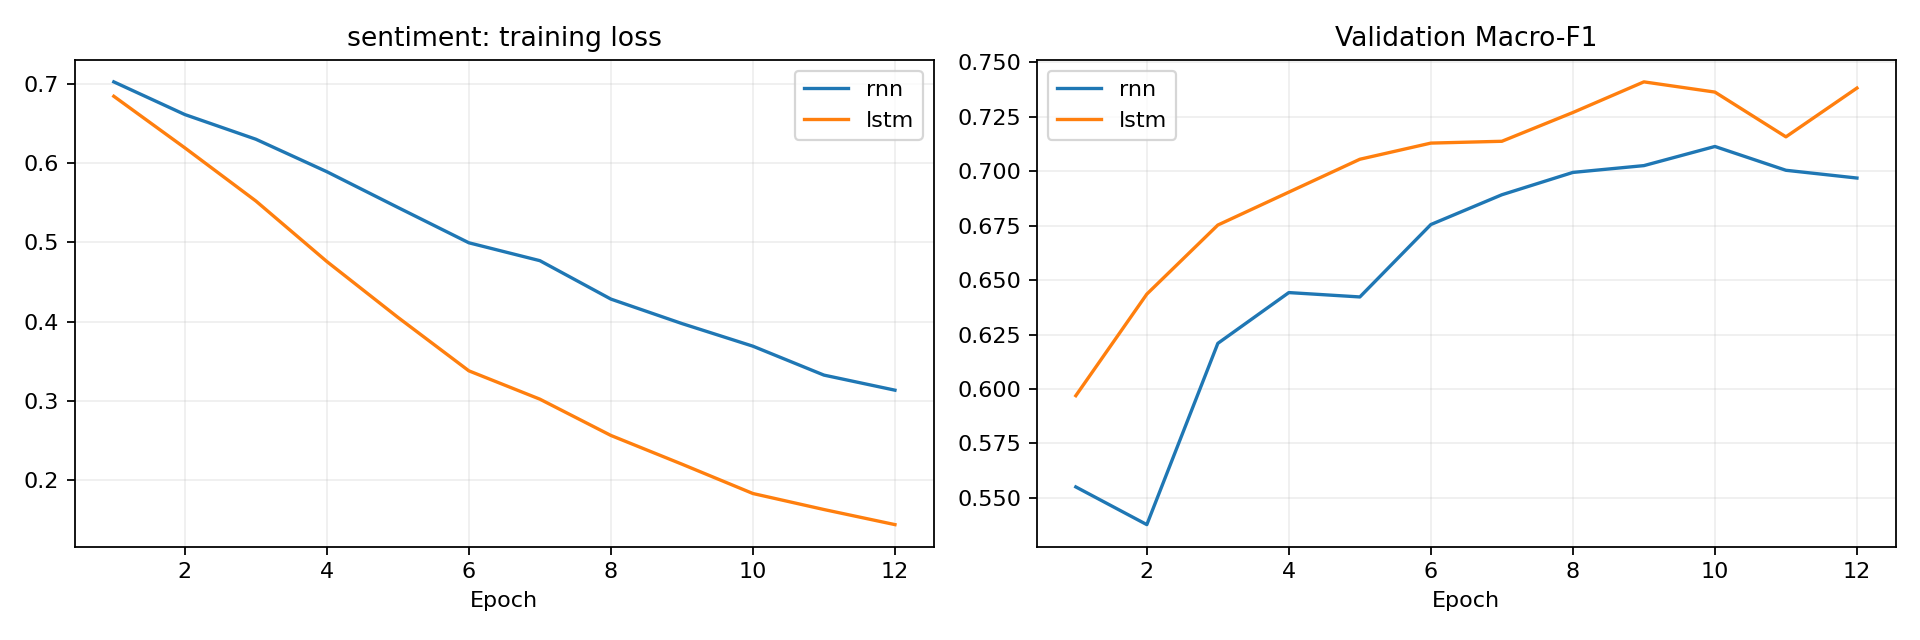

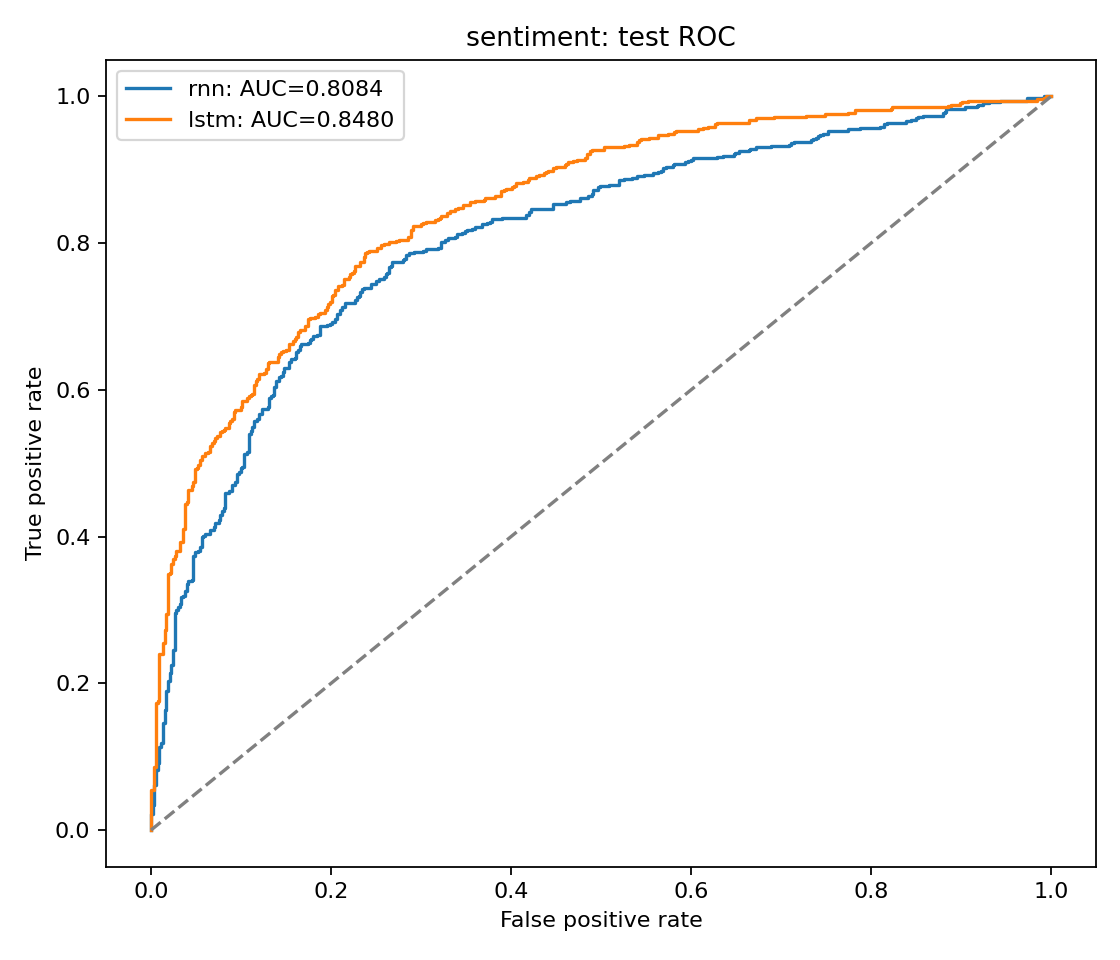

In [3]:
display(pd.read_csv(R/'sentiment_metrics.csv'))
show('sentiment_learning.png')
show('sentiment_roc.png')

需要重做訓練時，可在 Colab Runner 執行全部實驗，或在已安裝相依套件與備份結果的 Week4 目錄執行 `python quiz2_sentiment.py`。訓練迴圈含 loss.backward、gradient clipping、optimizer.step 與 validation checkpoint selection；程式完整保留在同名檔案。

## 使用測試資料推論

0=負面，1=正面；下表為固定 test 前十二筆，完整預測已存 CSV。

In [4]:
for model in ['rnn','lstm']:
    print(model.upper())
    display(pd.read_csv(R/f'predictions/sentiment_{model}.csv').head(12))

RNN


,id,true,predicted,p_0,p_1,text
0,0,1,1,0.295124,0.704876,lovingly photographed in the manner of a golde...
1,1,1,1,0.282550,0.717450,consistently clever and suspenseful .
2,2,1,0,0.948794,0.051206,"it's like a "" big chill "" reunion of the baade..."
3,3,1,0,0.694757,0.305243,the story gives ample opportunity for large-sc...
4,4,1,1,0.138803,0.861196,"red dragon "" never cuts corners ."
5,5,1,0,0.969979,0.030020,fresnadillo has something serious to say about...
6,6,1,1,0.021023,0.978977,throws in enough clever and unexpected twists ...
7,7,1,1,0.471380,0.528620,weighty and ponderous but every bit as filling...
8,8,1,0,0.973225,0.026775,a real audience-pleaser that will strike a cho...
9,9,1,1,0.061867,0.938133,generates an enormous feeling of empathy for i...


LSTM


,id,true,predicted,p_0,p_1,text
0,0,1,0,0.974035,0.025965,lovingly photographed in the manner of a golde...
1,1,1,1,0.117826,0.882174,consistently clever and suspenseful .
2,2,1,0,0.527162,0.472838,"it's like a "" big chill "" reunion of the baade..."
3,3,1,0,0.959346,0.040654,the story gives ample opportunity for large-sc...
4,4,1,1,0.193589,0.806411,"red dragon "" never cuts corners ."
5,5,1,1,0.028095,0.971905,fresnadillo has something serious to say about...
6,6,1,1,0.006561,0.993439,throws in enough clever and unexpected twists ...
7,7,1,1,0.036484,0.963516,weighty and ponderous but every bit as filling...
8,8,1,1,0.464573,0.535427,a real audience-pleaser that will strike a cho...
9,9,1,1,0.008496,0.991504,generates an enormous feeling of empathy for i...


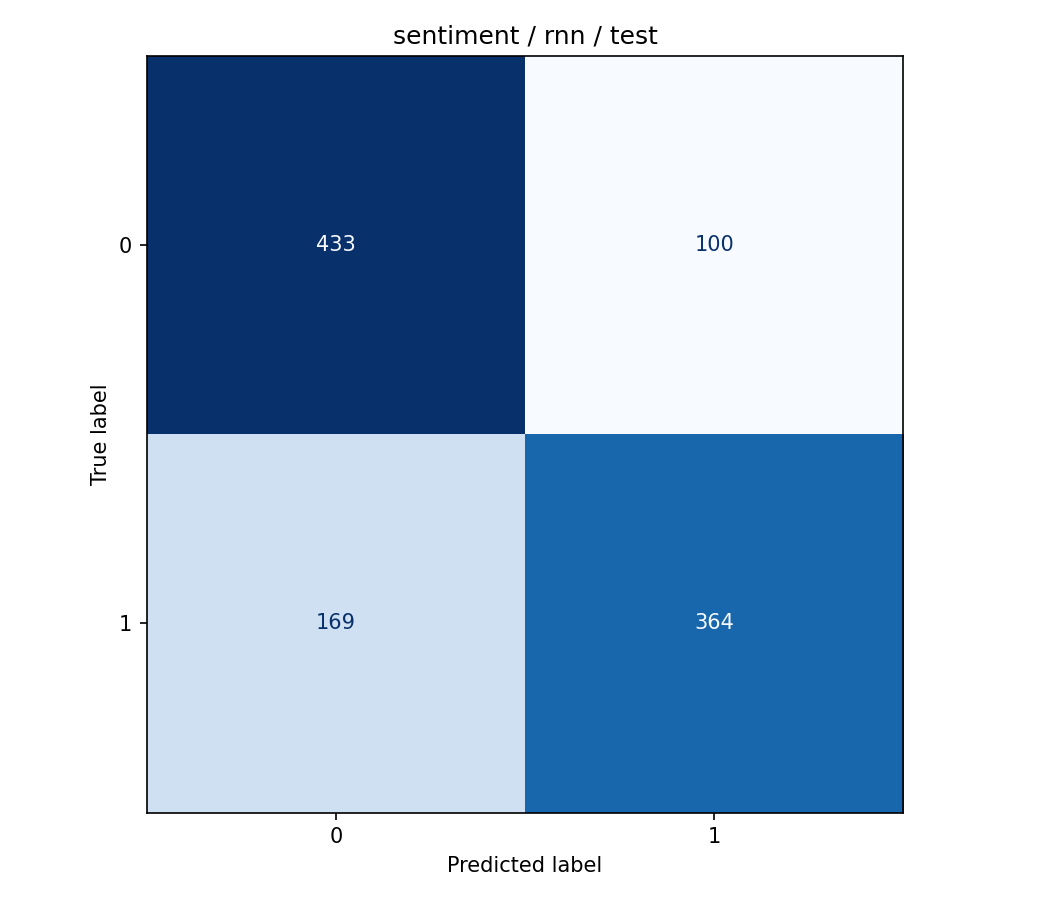

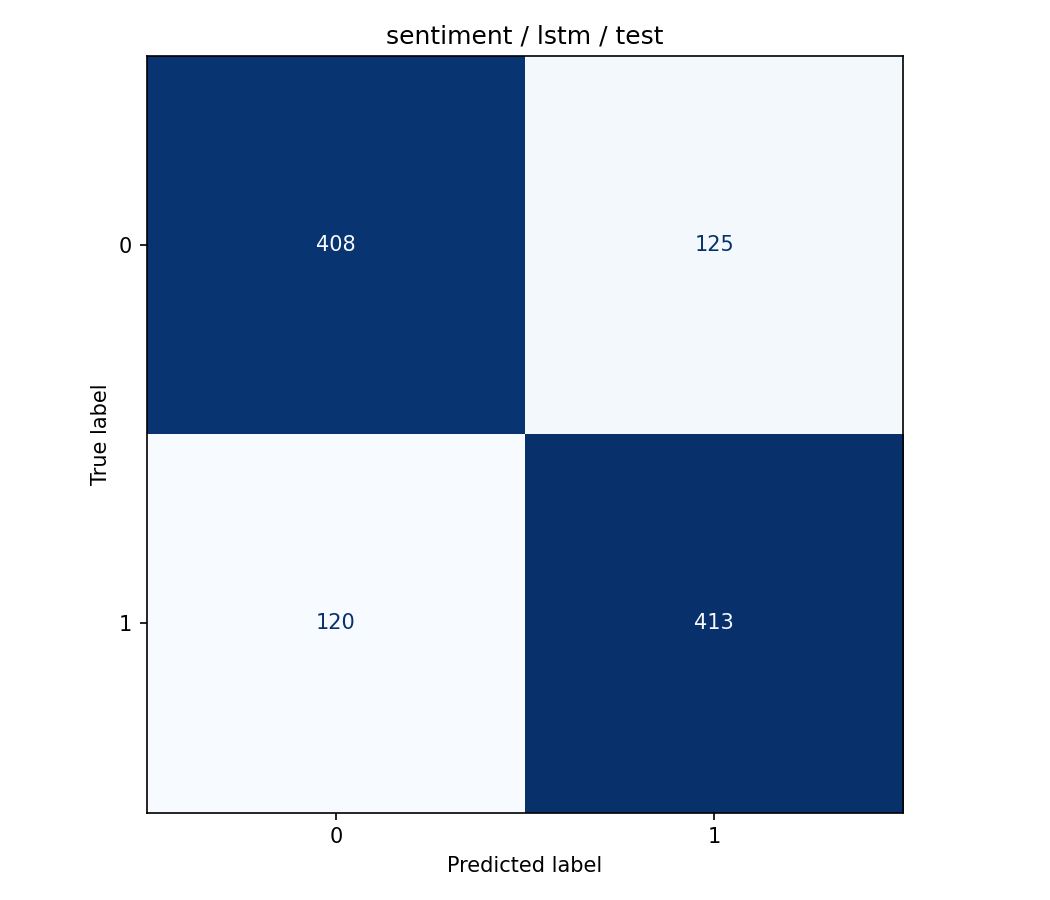

In [5]:
show('sentiment_rnn_confusion.png')
show('sentiment_lstm_confusion.png')

## 解讀

Accuracy 表示分類正確率；Macro-F1 平等重視正負兩類；ROC-AUC 衡量連續正面機率的排序能力。僅有一個 seed，且兩種 recurrent unit 參數量不同，不宜將結果視為架構的普遍結論。完整數據分析見 REPORT.md。